# Dual control of an integrator with unknown gain

This notebook runs the dual control problem of Åström and Helmersson (1986, Sec. 2): an integrator whose input gain is unknown,

$$y_{t+1} = y_t + b\,u_t + \sigma e_{t+1}, \qquad e_t \sim \mathcal{N}(0, 1), \qquad b \sim \mathcal{N}(b_0, P_0),$$

with the loss $L = \sum_{t=1}^{T} y_t^2 / \sigma^2$. The controller knows $\sigma$ and the prior of the gain, and given the data the gain has the Gaussian posterior $\mathcal{N}(\hat b_t, P_t)$ of a scalar Kalman filter. The paper defines the problem but no benchmark protocol, because its simulations concern a slowly varying gain. The protocol here is therefore ours: regulation from $y_0 = 0$ over $T = 50$ steps with $\sigma = 0.1$ and $P_0 = 1$, the gain drawn from its prior in every episode, and the prior means $b_0 \in \{0, 0.5, 1, 2, 4\}$.

In the normalised variables $\eta = y/\sigma$, $\beta = \hat b/\sqrt{P}$ and $\nu = u\sqrt{P}/\sigma$, one step of the filter reads $\eta' = \eta + \beta\nu + \sqrt{1+\nu^2}\,w$ and $\beta' = \beta\sqrt{1+\nu^2} + \nu w$ with $w \sim \mathcal{N}(0, 1)$, the paper's (2.5)–(2.6). The Bellman equation (2.8) of the unconstrained problem therefore lives on $(\eta, \beta)$, and `integrator.DualDP` solves it on a grid with the numerics of the paper's Sec. 3; Section 1 checks it against the paper's figures. Its expected loss is the optimum and a lower bound for every controller below. With a known gain the expected loss is $T = 50$, and the paper calls the excess the learning loss. The prior gain estimate $b_0$ equals $\beta_0$ here, the ratio of what the controller believes about the gain to how uncertain it is. Small $\beta_0$ is the regime where the cautious controller turns off.

| controller | decision rule |
|---|---|
| certainty equivalence | $u = -y/\hat b$, clipped; at $\hat b = 0$ its limit, the full input against the output |
| cautious | $u = -\hat b y/(\hat b^2 + P)$, clipped: the one-step optimum, which turns off for small $\beta$ |
| optimal dual (DP) | one-step lookahead on the value functions of the Bellman equation, unconstrained |
| approximate dual (5.1) | the paper's closed-form approximation of the optimal law for $T = 31$, unconstrained |
| CBFE-ARX, β = 0 | constrained Bethe planner without the information constraint (cautious, 5-step horizon) |
| CBFE-ARX, β = 1 (EFE) | expected free energy, i.e. a unit multiplier |
| CBFE-ARX, KKT β | the information constraint with the task floor of the paper |
| CBFE-ARX, KKT β, floor −H[p*] | the earlier floor, the negative entropy of the goal prior |
| dual MPC | fixed probing weight λ, chosen on held-out seeds |
| MPC-X | the experiment-design constraint of Larsson et al. (ECC 2013), accuracy γ chosen on held-out seeds |

All controllers except the two unconstrained ones keep $|u| \le 1$. The ARX agents of `agents/` run on the benchmark's Bayesian model: features $(1, u, y)$, the intercept and the pole known, the gain with prior $\mathcal{N}(b_0, P_0)$, the noise known, so that their parameter posterior is the Kalman filter. Their goal prior is $\mathcal{N}(0, \sigma^2)$, as tight as the noise allows. With this goal, the floor of the information constraint is $\tfrac{1}{2}\ln \bar\ell^*_t$: the agent demands information while the gain's spread at the goal-reaching inputs exceeds the noise.

The episodes come from `run.py` (`run.py tune`, then `run.py`), which writes `results/tuning.pkl` and `results/benchmark.pkl`. The first run solves the dynamic program (about three minutes on 24 cores) and caches it.

1. The dynamic program reproduces the paper
2. The optimal dual control law
3. Tuning of the baselines
4. Loss against the prior
5. Turn-off and computation
6. An episode
7. The information multiplier
8. Takeaways

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'experiment-integrator' / 'integrator.py').exists()) / 'experiment-integrator'
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

import integrator as I
import run as Run

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.width', 200)
bench = I.Benchmark()
dp = I.dual_dp(bench.T)
print(bench)

Benchmark(sigma=0.1, b0=0.0, P0=1.0, T=50, u_max=1.0, K=5, known=1000000.0, nu0=10000.0)


## 1. The dynamic program reproduces the paper

The left panel recomputes the paper's Fig. 3, the optimal input at $\eta = 0$ against $\beta$ for $T = 3$, 6, 11 and 31 steps to go; the markers are read off the paper. The right panel recomputes its Fig. 1, the learning loss $U_3(0, \beta, \nu) - 3$ of an input $\nu$ near the jump of the three-step law. The first table compares the laws, the second the expected loss of the paper's approximation (5.1) over 31 steps with the optimum.

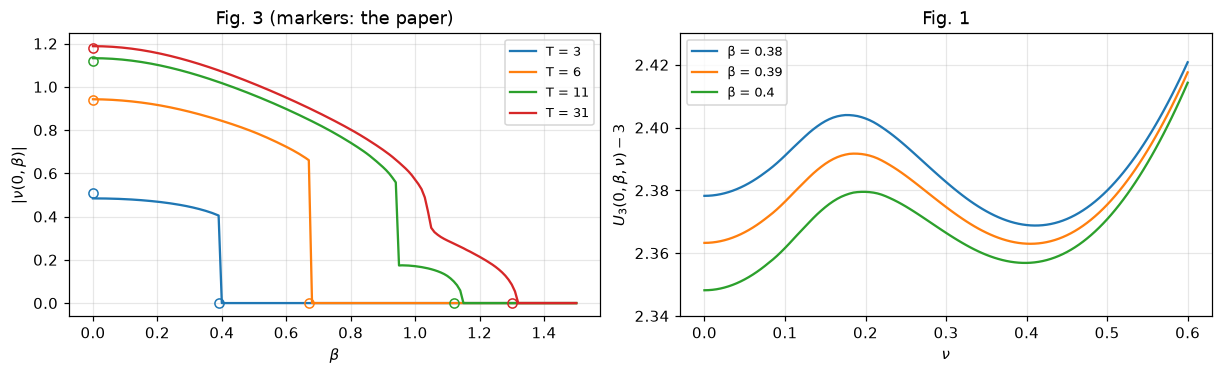

,"ν(0, 0), paper","ν(0, 0), DP","probing ends at β, paper","probing ends at β, DP"
T = 3,0.51,0.48,0.39,0.39
T = 6,0.94,0.94,0.67,0.67
T = 11,1.12,1.13,1.12,1.14
T = 31,1.18,1.19,1.30,1.31


,"optimum V_31(0, β0)",approximation (5.1),gap
0.0,39.98,40.08,0.11
0.5,39.75,39.85,0.10
1.0,38.76,38.88,0.12
2.0,34.75,34.88,0.13
4.0,32.17,32.23,0.06


In [2]:
PAPER = {3: (0.51, 0.39), 6: (0.94, 0.67), 11: (1.12, 1.12), 31: (1.18, 1.30)}   # Fig. 3: nu(0, 0), end of probing
betas = np.linspace(0.0, 1.5, 151)
law = {k: np.array([abs(dp.nu(k, 0.0, b)) for b in betas]) for k in PAPER}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.3), layout='constrained')
for i, k in enumerate(PAPER):
    axs[0].plot(betas, law[k], color=f'C{i}', label=f'T = {k}')
    axs[0].plot([0.0, PAPER[k][1]], [PAPER[k][0], 0.0], 'o', color=f'C{i}', mfc='none')
axs[0].set(xlabel=r'$\beta$', ylabel=r'$|\nu(0, \beta)|$', title="Fig. 3 (markers: the paper)")
axs[0].legend(fontsize='small')
nus = np.linspace(0.0, 0.6, 121)
for i, b in enumerate((0.38, 0.39, 0.40)):
    axs[1].plot(nus, [float(dp.q_value(3, 0.0, b, n)) - 3 for n in nus], color=f'C{i}', label=f'β = {b}')
axs[1].set(xlabel=r'$\nu$', ylabel=r'$U_3(0, \beta, \nu) - 3$', title='Fig. 1', ylim=(2.34, 2.43))
axs[1].legend(fontsize='small')
plt.show()
display(pd.DataFrame({
    'ν(0, 0), paper': {f'T = {k}': PAPER[k][0] for k in PAPER},
    'ν(0, 0), DP': {f'T = {k}': law[k][0] for k in PAPER},
    'probing ends at β, paper': {f'T = {k}': PAPER[k][1] for k in PAPER},
    'probing ends at β, DP': {f'T = {k}': betas[np.nonzero(law[k] > 1e-3)[0][-1]] for k in PAPER},
}).round(2))
approx = I.policy_values(dp, I.approximate_dual_law, 31)
gap = pd.DataFrame({b0: {'optimum V_31(0, β0)': float(dp.value(31, 0.0, b0)),
                         'approximation (5.1)': float(approx.value(31, 0.0, b0))} for b0 in Run.B0}).T
gap['gap'] = gap['approximation (5.1)'] - gap['optimum V_31(0, β0)']
gap.round(2)

The dynamic program reproduces the paper. The optimal input at η = 0 starts at 0.48, 0.94, 1.13 and 1.19 for 3, 6, 11 and 31 steps to go, against 0.51, 0.94, 1.12 and 1.18 read off the paper's Fig. 3, and probing ends at β = 0.39, 0.67, 1.14 and 1.31, against 0.39, 0.67, 1.12 and 1.30. The three-step law jumps from ν ≈ 0.4 to zero at β = 0.39, because the two local minima of $U_3(0, \beta, \nu)$ at ν = 0 and ν ≈ 0.41 exchange order there (2.3633 against 2.3630), as in the paper's Fig. 1. The approximation (5.1) loses 0.06–0.13 more than the optimum over 31 steps from η = 0, and at most 0.26 over η, β ≤ 10, where the paper reports 0.2. The laws for 31 and 50 steps differ by at most 0.009 for η > 0, as the paper finds for 31 and 100 steps (0.012). Only the small arc of height about 0.03 near β = 1.25 in the paper's Fig. 3 does not appear. The grid has converged: with 181 instead of 121 points per axis, $V_{31}$ changes by at most 0.004 and the law by at most 0.01.

## 2. The optimal dual control law

The figure shows the normalised input $\nu$ of the optimal dual controller against $\beta$ for three normalised outputs $\eta$, with 50 and with 5 steps to go, together with the paper's approximation (5.1), the cautious and the certainty-equivalent laws.

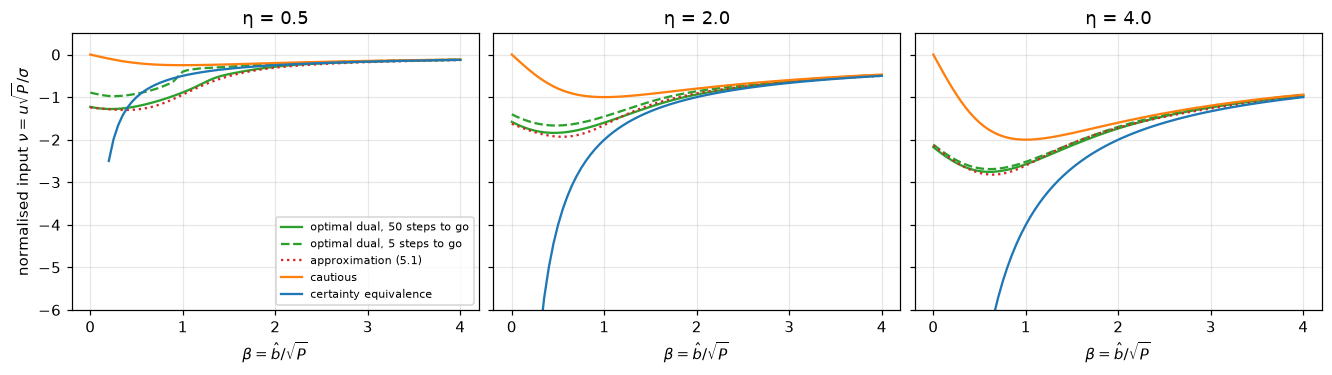

optimal expected loss V_T(0, beta0): {0.0: 59.4, 0.5: 59.2, 1.0: 58.2, 2.0: 54.2, 4.0: 51.5}


In [3]:
betas = np.linspace(0.0, 4.0, 81)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.3), layout='constrained', sharey=True)
for ax, eta in zip(axs, (0.5, 2.0, 4.0)):
    ax.plot(betas, [dp.nu(bench.T, eta, b) for b in betas], color='C2', label=f'optimal dual, {bench.T} steps to go')
    ax.plot(betas, [dp.nu(5, eta, b) for b in betas], '--', color='C2', label='optimal dual, 5 steps to go')
    ax.plot(betas, I.approximate_dual_law(eta, betas), ':', color='C3', label='approximation (5.1)')
    ax.plot(betas, -eta * betas / (1 + betas**2), color='C1', label='cautious')
    ax.plot(betas[4:], -eta / betas[4:], color='C0', label='certainty equivalence')
    ax.set(title=f'η = {eta}', xlabel=r'$\beta = \hat b/\sqrt{P}$', ylim=(-6, 0.5))
axs[0].set_ylabel(r'normalised input $\nu = u\sqrt{P}/\sigma$')
axs[0].legend(fontsize='x-small', loc='lower right')
plt.show()
print('optimal expected loss V_T(0, beta0):', {b0: round(float(dp.value(bench.T, 0.0, b0)), 1) for b0 in Run.B0})

The optimal dual controller probes where the cautious law turns off. At β = 0 the cautious input is zero for every output, because an input only adds variance when the sign of the gain is unknown, and the certainty-equivalent input is unbounded. The optimal input is instead ν ≈ −1.2, −1.6 and −2.2 at η = 0.5, 2 and 4: it spreads the next output by 1.2–2.2 noise standard deviations to learn the sign of the gain. As β grows, all laws converge, because a well-known gain leaves nothing to learn. With 5 steps to go, the optimal controller probes less than with 50 (ν = −0.89 against −1.23 at η = 0.5), and the approximation (5.1) follows the optimal law to within about 0.1. The optimal expected loss is 59.4 for b0 = 0 and 51.5 for b0 = 4, against 50 for a known gain, so not knowing the gain costs at most 9.4.

## 3. Tuning of the baselines

The dual MPC needs a probing weight λ and MPC-X an accuracy γ. Both were chosen on held-out seeds 1000-1049 by the mean loss over all priors, the protocol of the arm experiments. The table lists the mean loss per prior.

In [4]:
tuning = pd.DataFrame([dict(label=r['label'], b0=r['b0'], loss=r['loss']) for r in I.load('tuning')])
table = tuning.pivot_table(index='label', columns='b0', values='loss', aggfunc='mean', sort=False)
table['all'] = tuning.groupby('label', sort=False).loss.mean()
table.round(1)

b0,0.0,0.5,1.0,2.0,4.0,all
label,,,,,,
"dual MPC, λ = 0",1000.2,77.9,85.8,57.6,50.9,254.5
"dual MPC, λ = 0.5",950.6,77.4,87.5,57.4,50.8,244.7
"dual MPC, λ = 2",101.7,79.3,98.2,57.4,50.8,77.5
"dual MPC, λ = 10",77.7,79.5,105.0,79.2,52.4,78.8
"dual MPC, λ = 50",100.3,94.2,119.5,105.5,94.6,102.8
"MPC-X, γ = 0.01",765.4,78.9,98.7,55.7,50.8,209.9
"MPC-X, γ = 0.03",196.5,78.9,98.7,55.7,50.8,96.1
"MPC-X, γ = 0.1",86.9,78.9,98.7,55.7,50.8,74.2
"MPC-X, γ = 0.3",105.6,78.9,98.7,55.7,50.8,77.9


The dual MPC is best with λ = 2 (mean loss 77.5) and MPC-X with γ = 0.1 (74.2); both values are used below. The choice trades the priors off. With λ ≤ 0.5, the dual MPC turns off at b0 = 0 (950–1000), and with λ ≥ 10 it keeps probing when the gain is known (b0 = 2: 79–106 against 57). MPC-X with γ ≤ 0.03 demands too little information at b0 = 0, and with γ = 1 it excites too much at b0 = 0.5–2.

## 4. Loss against the prior

The table lists the mean loss per controller and prior over 200 seeds, the figure the mean with its standard error and the ratio to the optimal dual controller on the same seeds.

In [5]:
results = I.load('benchmark')
df = pd.DataFrame([dict(label=r['label'], b0=r['b0'], seed=r['seed'], loss=r['loss'], b=r['episode'].b,
                        moved=bool(np.any(np.abs(r['episode'].u) > 1e-6)),
                        plan_ms=1000 * r['episode'].plan_time.mean()) for r in results])
order = list(Run.controllers())
df['label'] = pd.Categorical(df.label, order, ordered=True)
optimum = {b0: float(dp.value(bench.T, 0.0, b0)) for b0 in Run.B0}
mean = df.pivot_table(index='label', columns='b0', values='loss', aggfunc='mean', observed=True)
mean['all'] = df.groupby('label', observed=True).loss.mean()
print(f'{len(results)} episodes, {df.seed.nunique()} seeds per controller and prior')
mean.round(1)

10000 episodes, 200 seeds per controller and prior


b0,0.0,0.5,1.0,2.0,4.0,all
label,,,,,,
certainty equivalence,188.4,112.2,86.1,56.1,50.4,98.6
cautious,1232.6,151.5,102.1,55.9,50.4,318.5
optimal dual (DP),57.9,58.3,57.0,52.9,50.3,55.3
approximate dual (5.1),58.4,58.7,58.1,53.1,50.4,55.7
"CBFE-ARX, β = 0",1232.6,128.9,102.3,56.1,50.4,314.1
"CBFE-ARX, β = 1 (EFE)",1232.6,127.5,98.7,55.9,50.4,313.0
"CBFE-ARX, KKT β",121.1,134.0,101.5,56.4,50.4,92.7
"CBFE-ARX, KKT β, floor −H[p*]",147.2,161.4,148.6,142.5,143.5,148.6
"dual MPC, λ = 2",155.5,107.3,99.4,55.9,50.4,93.7


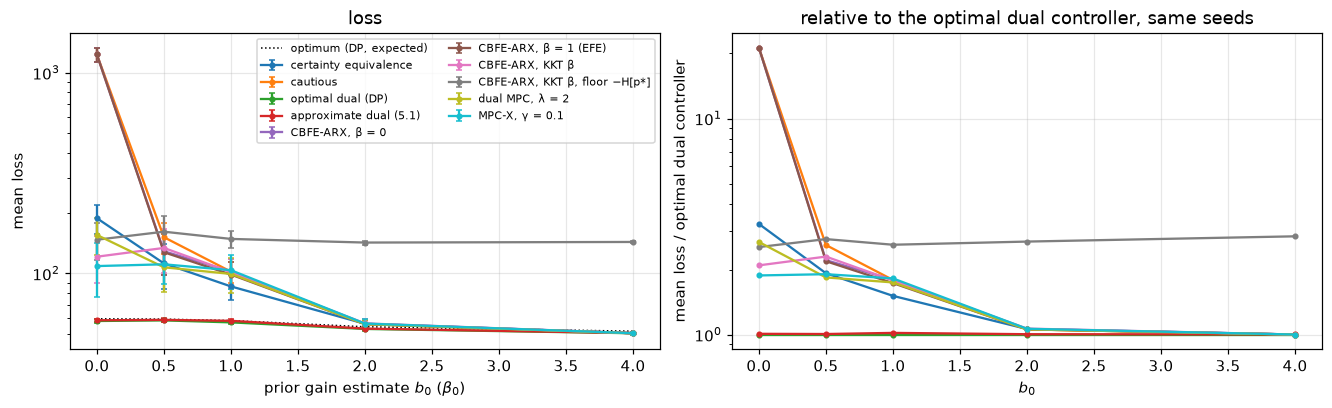

loss with a known gain on these seeds: 48.7 (expected 50)
learning loss of the optimal dual controller, mean (expected): {0.0: '9.2 (9.4)', 0.5: '9.6 (9.2)', 1.0: '8.3 (8.2)', 2.0: '4.2 (4.2)', 4.0: '1.6 (1.5)'}


b0,"median, b0=0.0","median, b0=0.5","median, b0=1.0","median, b0=2.0","median, b0=4.0"
label,,,,,
certainty equivalence,113.9,60.2,55.6,50.7,48.9
cautious,742.4,73.1,56.5,50.9,48.9
optimal dual (DP),55.5,55.8,54.7,50.4,48.7
approximate dual (5.1),56.3,56.0,54.6,50.6,49.2
"CBFE-ARX, β = 0",742.4,60.5,55.6,50.6,48.9
"CBFE-ARX, β = 1 (EFE)",742.4,58.1,55.5,50.4,48.9
"CBFE-ARX, KKT β",69.2,58.8,55.7,50.9,48.9
"CBFE-ARX, KKT β, floor −H[p*]",108.4,110.9,119.2,135.4,138.4
"dual MPC, λ = 2",82.4,58.3,55.2,50.4,48.9


In [6]:
COLORS = {label: f'C{i}' for i, label in enumerate(order)}
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), layout='constrained')
g = df.groupby(['label', 'b0'], observed=True).loss
reference = g.mean()['optimal dual (DP)']
for label in order:
    m, se = g.mean()[label], g.sem()[label]
    axs[0].errorbar(m.index, m, yerr=se, marker='o', ms=3, capsize=2, color=COLORS[label], label=label)
    axs[1].plot(m.index, m / reference, marker='o', ms=3, color=COLORS[label])
axs[0].plot(list(optimum), list(optimum.values()), 'k:', lw=1, label='optimum (DP, expected)')
axs[0].set(yscale='log', xlabel=r'prior gain estimate $b_0$ ($\beta_0$)', ylabel='mean loss', title='loss')
axs[1].set(yscale='log', xlabel=r'$b_0$', ylabel='mean loss / optimal dual controller',
           title='relative to the optimal dual controller, same seeds')
axs[0].legend(fontsize='x-small', ncol=2)
plt.show()
known = np.mean([I.known_gain_loss(bench, s) for s in Run.SEEDS])
print(f'loss with a known gain on these seeds: {known:.1f} (expected {bench.T})')
print('learning loss of the optimal dual controller, mean (expected):',
      {b0: f'{reference[b0] - known:.1f} ({optimum[b0] - bench.T:.1f})' for b0 in Run.B0})
(df.groupby(['label', 'b0'], observed=True).loss.median().unstack('b0').round(1)
   .rename(columns=lambda c: f'median, b0={c}'))

The means are dominated by gains near zero, for which no controller with $|u| \le 1$ can correct the drift of the integrator. The table repeats them for the episodes with $|b| > 0.3$. On this subset the optimal dual controller is a reference, not a bound, because it minimises the loss averaged over the prior.

In [7]:
big = df[df.b.abs() > 0.3]
table = big.pivot_table(index='label', columns='b0', values='loss', aggfunc='mean', observed=True)
table['all'] = big.groupby('label', observed=True).loss.mean()
print(f'{len(big) // len(order)} of {len(df) // len(order)} episodes per controller have |b| > 0.3')
table.round(1)

882 of 1000 episodes per controller have |b| > 0.3


b0,0.0,0.5,1.0,2.0,4.0,all
label,,,,,,
certainty equivalence,170.0,69.1,61.1,53.0,50.4,78.4
cautious,1275.1,84.6,63.8,52.3,50.4,285.7
optimal dual (DP),56.2,55.9,55.4,52.2,50.3,53.8
approximate dual (5.1),56.4,56.5,56.6,52.3,50.4,54.2
"CBFE-ARX, β = 0",1275.1,57.5,56.8,52.3,50.4,279.6
"CBFE-ARX, β = 1 (EFE)",1275.1,57.0,55.1,52.1,50.4,279.2
"CBFE-ARX, KKT β",72.3,59.0,57.0,52.6,50.4,57.7
"CBFE-ARX, KKT β, floor −H[p*]",115.4,118.8,125.1,140.7,143.5,129.8
"dual MPC, λ = 2",107.2,57.1,55.1,52.1,50.4,63.3


Only the controllers that probe avoid turn-off under the symmetric prior b0 = 0. Cautious control and the CBFE-ARX agents with β = 0 and β = 1 never move, and their loss is that of the free random walk, 1233 on average against 58 for the optimal dual controller. EFE does not probe either, because its goal prior is as tight as the noise: then tr(S*⁻¹R)/n_y = 1, and a unit multiplier sits exactly at the probing threshold. Certainty equivalence applies the full input while its estimate is zero, and afterwards u = −y/b̂ is too large while the estimate is small. It loses 188, the start-up failure the paper describes. The CBFE-ARX agent with the task floor moves from the first step.

For |b| > 0.3, the CBFE-ARX agent with the task floor loses 72 at b0 = 0, against 56 for the optimum, 67 for MPC-X, 107 for the dual MPC and 170 for certainty equivalence. Over all priors it loses 57.7, against 53.8, 58.2, 63.3 and 78.4. It thus comes within 7 % of the optimal dual controller without a tuned parameter, and it matches MPC-X, whose accuracy was tuned on held-out seeds. For b0 ≥ 0.5, all controllers with a nonzero gain estimate learn while they regulate, and the task floor adds little: the CBFE-ARX agent with and without the constraint loses 59.0 and 57.5 at b0 = 0.5 (|b| > 0.3). Certainty equivalence beats the CBFE-ARX agents over all episodes at b0 = 0.5 (112 against 128–134) but not for |b| > 0.3 (69 against 57–59). Its large inputs thus pay off only when the gain is so small that the bound |u| ≤ 1 binds. The earlier floor −H[p*] is 0.88 nats here, which no input can deliver, so it saturates the multiplier at every prior and multiplies the loss by 2.5–2.9, even when the gain is known (143 against 50 at b0 = 4).

The benchmark confirms the dynamic program in two ways. The paper's approximation (5.1) loses 0.4 more than the optimal dual controller over all episodes (55.7 against 55.3). Moreover, the optimal dual controller's mean learning losses on these seeds, 9.2, 9.6, 8.3, 4.2 and 1.6 for b0 = 0 to 4, match the expected ones of the dynamic program, 9.4, 9.2, 8.2, 4.2 and 1.5, within one standard error (about 1.1).

## 5. Turn-off and computation

The fraction of episodes in which a controller never moves the input, and the mean computation time per step.

In [8]:
summary = pd.concat({
    'never moves': df.groupby(['label', 'b0'], observed=True).moved.apply(lambda m: 1 - m.mean()).unstack('b0'),
    'ms per step': df.groupby('label', observed=True).plan_ms.mean().to_frame('all'),
}, axis=1)
summary.round(3)

never moves                     ms per step
                                      0.0  0.5  1.0  2.0  4.0         all
label                                                                    
certainty equivalence                 0.0  0.0  0.0  0.0  0.0       0.004
cautious                              1.0  0.0  0.0  0.0  0.0       0.005
optimal dual (DP)                     0.0  0.0  0.0  0.0  0.0      56.641
approximate dual (5.1)                0.0  0.0  0.0  0.0  0.0       0.009
CBFE-ARX, β = 0                       1.0  0.0  0.0  0.0  0.0       2.660
CBFE-ARX, β = 1 (EFE)                 1.0  0.0  0.0  0.0  0.0       8.362
CBFE-ARX, KKT β                       0.0  0.0  0.0  0.0  0.0       6.678
CBFE-ARX, KKT β, floor −H[p*]         0.0  0.0  0.0  0.0  0.0      48.682
dual MPC, λ = 2                       0.0  0.0  0.0  0.0  0.0       5.275
MPC-X, γ = 0.1                        0.0  0.0  0.0  0.0  0.0       3.465

At b0 = 0, cautious control and the CBFE-ARX agents with β = 0 and β = 1 never move the input in any of the 200 episodes. Every other controller moves in every episode, certainty equivalence included, because its limit at b̂ = 0 is the full input. The CBFE-ARX agent with the task floor needs 7 ms per step and the agent with the earlier floor 49 ms, because its multiplier is positive on every step, so that the planner also solves the one-step program from the corners of the input box and sweeps from a second start. The optimal dual controller needs 57 ms for its one-step lookahead on the precomputed value functions, which evaluates the expectation with 56 quadrature nodes per candidate input.

## 6. An episode

Output, input and gain estimate of five controllers in one episode with $b_0 = 0$.

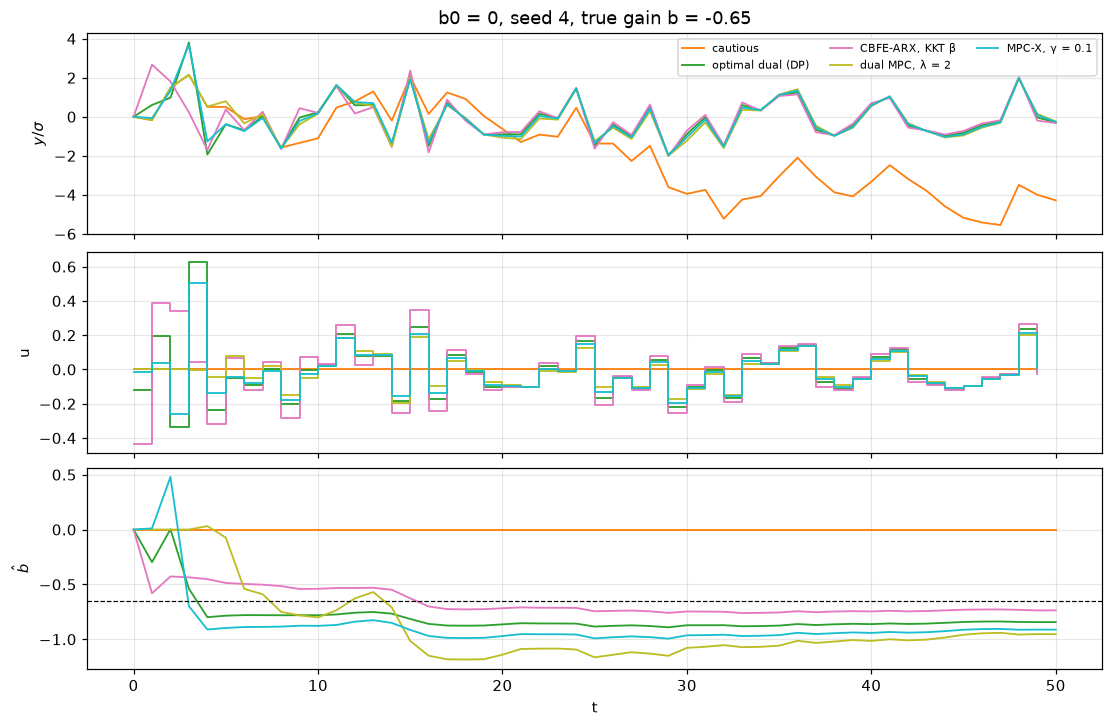

In [9]:
seed = next(r['seed'] for r in results if r['label'] == order[0] and r['b0'] == 0.0
            and 0.6 < abs(r['episode'].b) < 1.0)
show = ['cautious', 'optimal dual (DP)', 'CBFE-ARX, KKT β', f'dual MPC, λ = {Run.LAMBDA:g}', f'MPC-X, γ = {Run.GAMMA:g}']
eps = {r['label']: r['episode'] for r in results if r['b0'] == 0.0 and r['seed'] == seed and r['label'] in show}
fig, axs = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True, layout='constrained')
t = np.arange(bench.T + 1)
for label in show:
    ep = eps[label]
    axs[0].plot(t, ep.y / bench.sigma, color=COLORS[label], lw=1.2, label=label)
    axs[1].step(t[:-1], ep.u, where='post', color=COLORS[label], lw=1.2)
    axs[2].plot(t, ep.bhat, color=COLORS[label], lw=1.2)
axs[2].axhline(eps[show[0]].b, color='k', ls='--', lw=0.8)
axs[0].set(ylabel=r'$y/\sigma$', title=f'b0 = 0, seed {seed}, true gain b = {eps[show[0]].b:.2f}')
axs[1].set(ylabel='u')
axs[2].set(ylabel=r'$\hat b$', xlabel='t')
axs[0].legend(fontsize='x-small', ncol=3)
plt.show()

In this episode the gain is b = −0.65. The cautious controller never moves, its estimate stays at zero, and the output drifts to −5.5σ. The optimal dual controller probes with inputs of 0.1–0.6 and alternating sign for four steps, after which its estimate sits at −0.8. The CBFE-ARX agent with the task floor probes with u = −0.44 in the first step and with two further inputs of about 0.35, after which its estimate sits at −0.45 to −0.5. Both, like MPC-X, then keep the output within ±2.5σ. The dual MPC waits about five steps before its estimate moves, and the approximation (5.1), not shown, follows the optimal dual controller to within 0.01 in the input.

## 7. The information multiplier

The mean KKT multiplier of the CBFE-ARX agent over the episode, and the fraction of episodes in which the constraint is active, per prior.

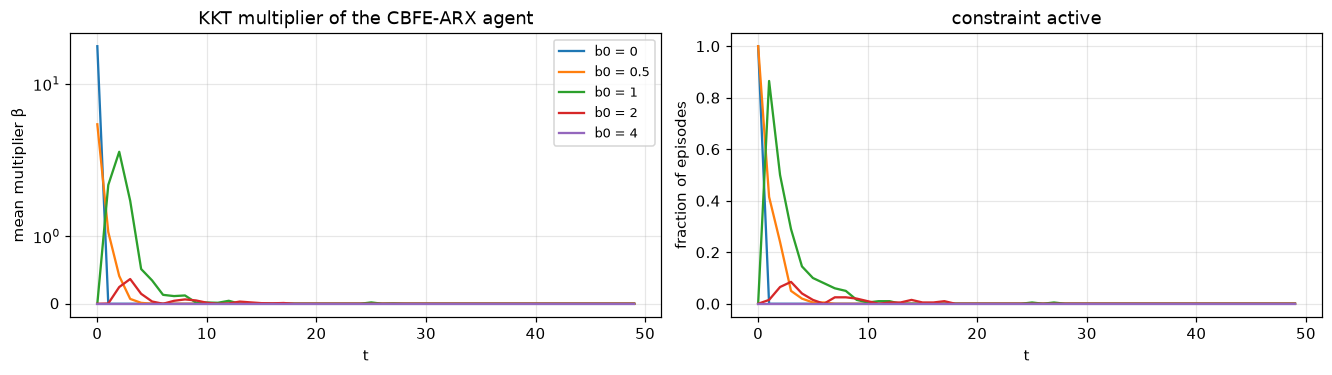

,0.0,0.5,1.0,2.0,4.0
"active, first 5 steps",0.2,0.345,0.36,0.041,0.0
"active, last 25 steps",0.0,0.000,0.00,0.000,0.0


In [10]:
kkt = [r for r in results if r['label'] == 'CBFE-ARX, KKT β']
fig, axs = plt.subplots(1, 2, figsize=(12, 3.3), layout='constrained')
for i, b0 in enumerate(Run.B0):
    B = np.array([r['episode'].beta for r in kkt if r['b0'] == b0])
    axs[0].plot(np.arange(bench.T), B.mean(axis=0), color=f'C{i}', label=f'b0 = {b0:g}')
    axs[1].plot(np.arange(bench.T), (B > 0).mean(axis=0), color=f'C{i}')
axs[0].set(xlabel='t', ylabel='mean multiplier β', yscale='symlog', title='KKT multiplier of the CBFE-ARX agent')
axs[1].set(xlabel='t', ylabel='fraction of episodes', title='constraint active')
axs[0].legend(fontsize='small')
plt.show()
pd.DataFrame({b0: {'active, first 5 steps': float(np.mean([np.mean(r['episode'].beta[:5] > 0) for r in kkt if r['b0'] == b0])),
                   'active, last 25 steps': float(np.mean([np.mean(r['episode'].beta[25:] > 0) for r in kkt if r['b0'] == b0]))}
              for b0 in Run.B0}).round(3)

The constraint is active only while the gain is uncertain relative to the goal. At b0 = 0, it is active in the first step of every episode (mean β ≈ 18) and off afterwards. At b0 = 0.5 and 1, it is active in the first three to five steps, as the output drifts and the inputs that reach the goal grow. It is active on 4 % of the first five steps at b0 = 2, never at b0 = 4, and never in the last 25 steps for any prior.

## 8. Takeaways

- **The dynamic program reproduces the paper.** It recovers the jumps of the paper's Figs. 1 and 3 (at β = 0.39 and 0.67 for 3 and 6 steps to go, and the end of probing at β ≈ 1.3 for 31 steps). The paper's approximation (5.1) loses only 0.4 more than it in the benchmark.
- **Under a symmetric prior, every controller without probing turns off.** Cautious control and the CBFE-ARX agents with β = 0 and β = 1 lose 1233 against 58 for the optimal dual controller. EFE turns off as well here, because a goal as tight as the noise puts the unit multiplier exactly at the probing threshold. Certainty equivalence does not turn off, but its inputs are too large while its estimate is small, and it loses 188.
- **The task floor probes when the gain is uncertain relative to the goal, and only then.** It is active in the first steps of an episode and never once the gain is known. For |b| > 0.3, the CBFE-ARX agent comes within 7 % of the optimal dual controller over all priors (57.7 against 53.8) without tuning. This is on a par with MPC-X (58.2) and ahead of the dual MPC (63.3), both tuned on held-out seeds, and of certainty equivalence (78.4).
- **The baselines need their tuning.** The dual MPC turns off with λ ≤ 0.5 and keeps probing known gains with λ ≥ 10; MPC-X probes too little with γ ≤ 0.03 and too much with γ = 1.
- **Gains near zero dominate the means.** With |b| < 0.3, the bound |u| ≤ 1 limits every controller except the two unconstrained ones. The mean losses of the bounded probing controllers are therefore 1.7–2.7 times the optimum at b0 ≤ 1, whereas for |b| > 0.3 the CBFE-ARX agent and MPC-X stay within 30 % of it at every prior.
- **The earlier floor −H[p*] over-explores at every prior.** It is 0.88 nats with σ = 0.1 and saturates the multiplier, which multiplies the loss by 2.5–2.9 even when the gain is known.